In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shivamb/netflix-shows/netflix_titles.csv


# 🎬 Netflix Movies and TV Shows: Exploratory Data Analysis
Welcome to my data analysis project! The goal of this project is to explore the Netflix catalog to uncover key insights about content types, global distribution, and release trends.

### Libraries Used
* **Pandas & NumPy** for data manipulation and cleaning.
* **Matplotlib & Seaborn** for data visualization.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/kaggle/input/datasets/shivamb/netflix-shows/netflix_titles.csv')

# Display the first 5 rows to verify it loaded correctly
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
# Check dataset dimensions, column data types, and non-null counts
print("--- DATASET INFO ---")
df.info()

print("\n--- MISSING VALUES COUNT ---")
print(df.isnull().sum())

--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

--- MISSING VALUES COUNT ---
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration    

In [10]:
# Handle missing values for key columns
df['country'] = df['country'].fillna('Unknown')
df['director'] = df['director'].fillna('Not Given')
df['cast'] = df['cast'].fillna('Not Given')

# Drop rows with missing values where it's critical (like rating or date added)
df = df.dropna(subset=['date_added', 'rating'])

# Verify that missing values are cleaned up
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        3
listed_in       0
description     0
dtype: int64


/tmp/ipykernel_49/1194843131.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='type', palette='Set2')


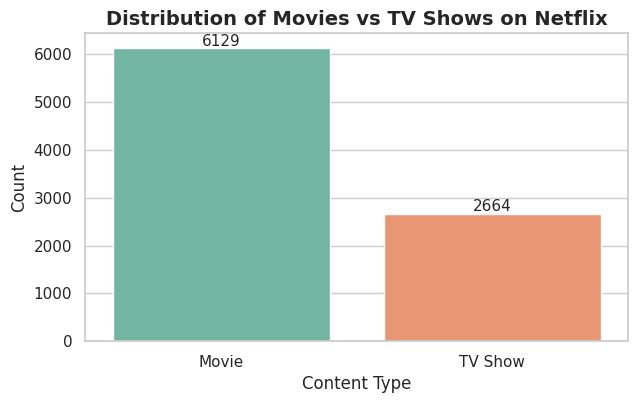

In [12]:
# Set the overall style for our plots
sns.set_theme(style="whitegrid")

# Create a figure for the count plot
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x='type', palette='Set2')

# Add title and labels
plt.title('Distribution of Movies vs TV Shows on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Content Type', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Display the exact count on top of the bars for extra polish
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points',
                fontsize=11)

plt.show()

/tmp/ipykernel_49/520210468.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_countries.values, y=top_countries.index, palette='crest')


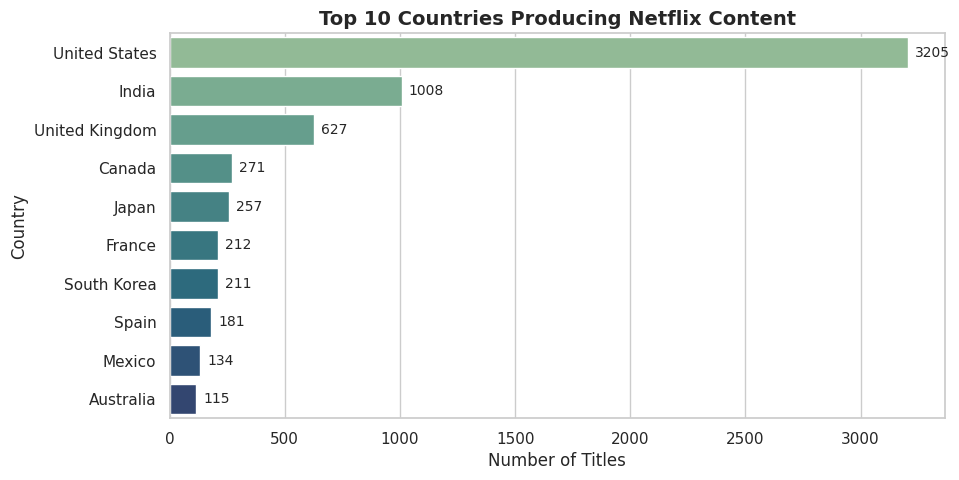

In [13]:
# Extract the primary country (since some rows have multiple comma-separated countries)
df['primary_country'] = df['country'].apply(lambda x: x.split(',')[0].strip())

# Get the top 10 countries (excluding 'Unknown')
top_countries = df[df['primary_country'] != 'Unknown']['primary_country'].value_counts().head(10)

# Create the bar plot
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top_countries.values, y=top_countries.index, palette='crest')

plt.title('Top 10 Countries Producing Netflix Content', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles', fontsize=12)
plt.ylabel('Country', fontsize=12)

# Add value labels to the end of each bar
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=10)

plt.show()

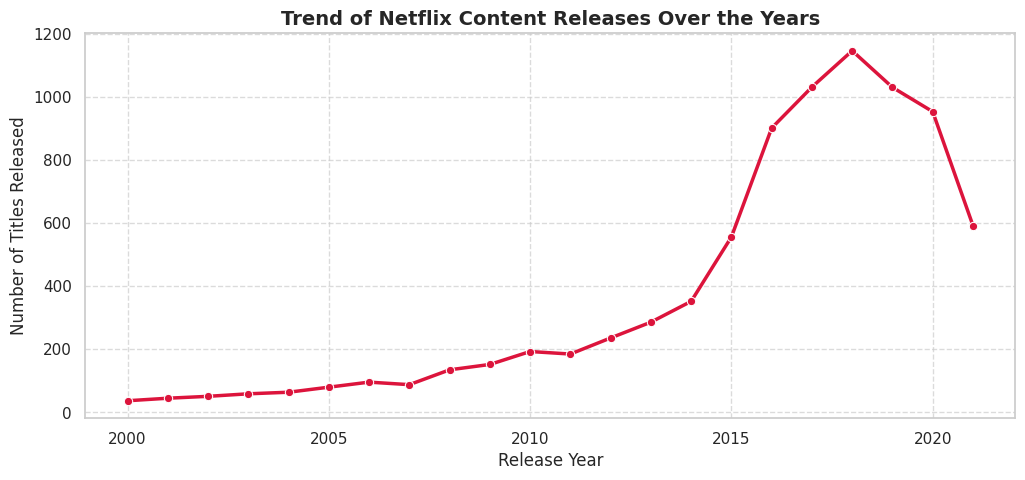

In [15]:
# Group by release year and count titles
yearly_trend = df['release_year'].value_counts().sort_index()

# Filter for recent years (e.g., from 2000 onwards) for a cleaner view
yearly_trend = yearly_trend[yearly_trend.index >= 2000]

# Create the line plot
plt.figure(figsize=(12, 5))
sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='crimson', linewidth=2.5)

plt.title('Trend of Netflix Content Releases Over the Years', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles Released', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()